GLOBAL TOKEN FREQUENCIES
shape: (10, 2)
┌────────────┬─────┐
│ token      ┆ len │
│ ---        ┆ --- │
│ str        ┆ u64 │
╞════════════╪═════╡
│ wire       ┆ 4   │
│ customer   ┆ 4   │
│ check      ┆ 3   │
│ transfer   ┆ 3   │
│ suspicious ┆ 3   │
│ account    ┆ 3   │
│ fraudulent ┆ 2   │
│ login      ┆ 2   │
│ deposited  ┆ 2   │
│ banking    ┆ 2   │
└────────────┴─────┘

TOP WORDS BY FRAUD CATEGORY

CHECK_FRAUD
shape: (5, 3)
┌─────────────┬───────────┬─────┐
│ category    ┆ token     ┆ len │
│ ---         ┆ ---       ┆ --- │
│ str         ┆ str       ┆ u64 │
╞═════════════╪═══════════╪═════╡
│ check_fraud ┆ check     ┆ 3   │
│ check_fraud ┆ deposited ┆ 2   │
│ check_fraud ┆ checks    ┆ 1   │
│ check_fraud ┆ withdrawn ┆ 1   │
│ check_fraud ┆ funds     ┆ 1   │
└─────────────┴───────────┴─────┘

WIRE_FRAUD
shape: (5, 3)
┌────────────┬────────────┬─────┐
│ category   ┆ token      ┆ len │
│ ---        ┆ ---        ┆ --- │
│ str        ┆ str        ┆ u64 │
╞════════════╪════════════╪═════

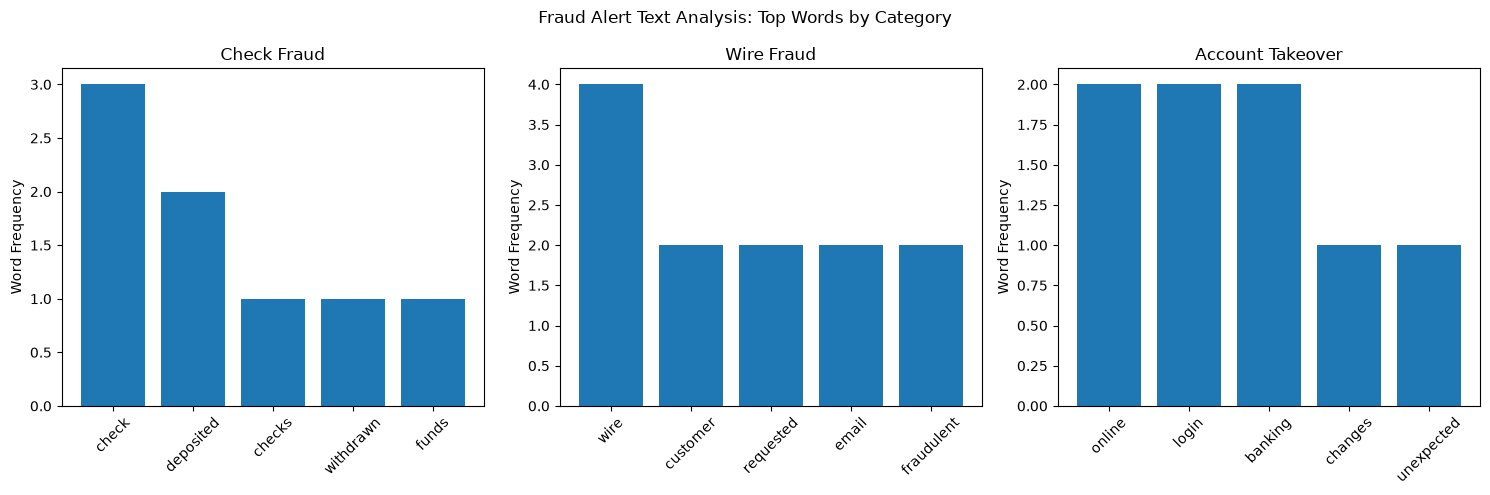


Phase 5 fraud text exploration completed successfully.
Documents analyzed: 12
Categories analyzed: 3


In [ ]:
from collections import Counter, defaultdict
from itertools import pairwise

import matplotlib.pyplot as plt
import polars as pl

# Phase 5: Fraud Text Exploration
# All fraud alert descriptions are fictional.

corpus = [
    {
        "category": "check_fraud",
        "text": "A counterfeit check was deposited into the account.",
    },
    {
        "category": "check_fraud",
        "text": "The customer reported an altered check with a different payee.",
    },
    {
        "category": "check_fraud",
        "text": "A stolen check was presented for deposit at the branch.",
    },
    {
        "category": "check_fraud",
        "text": "Multiple suspicious checks were deposited and funds were withdrawn.",
    },
    {
        "category": "wire_fraud",
        "text": "The customer received fraudulent wire instructions by email.",
    },
    {
        "category": "wire_fraud",
        "text": "A suspicious wire transfer was requested to an unknown beneficiary.",
    },
    {
        "category": "wire_fraud",
        "text": "The customer was instructed to send a wire for an investment opportunity.",
    },
    {
        "category": "wire_fraud",
        "text": "A fraudulent email requested a wire transfer to a new account.",
    },
    {
        "category": "account_takeover",
        "text": "An unauthorized login was detected on the customer's online banking.",
    },
    {
        "category": "account_takeover",
        "text": "The customer reported an unexpected password reset notification.",
    },
    {
        "category": "account_takeover",
        "text": "A suspicious login was followed by changes to account information.",
    },
    {
        "category": "account_takeover",
        "text": "An unknown device accessed online banking and attempted a transfer.",
    },
]

stop_words = {
    "the",
    "was",
    "were",
    "and",
    "for",
    "with",
    "into",
    "from",
    "that",
    "this",
    "had",
    "has",
    "are",
    "not",
    "but",
    "been",
}


def tokenize(text):
    """Clean and tokenize fictional fraud descriptions."""
    tokens = text.lower().split()
    return [
        cleaned
        for token in tokens
        if (cleaned := token.strip(".,:;!?()[]\"'"))
        and len(cleaned) > 2
        and cleaned not in stop_words
    ]


# Create token records
records = []
for document in corpus:
    for token in tokenize(document["text"]):
        records.append({"category": document["category"], "token": token})

token_df = pl.DataFrame(records)

# Global word frequencies
global_freq = token_df.group_by("token").len().sort("len", descending=True)

print("GLOBAL TOKEN FREQUENCIES")
print(global_freq.head(10))

# Word frequencies by fraud category
category_freq = (
    token_df.group_by(["category", "token"])
    .len()
    .sort(["category", "len"], descending=[False, True])
)

print("\nTOP WORDS BY FRAUD CATEGORY")
for category in ["check_fraud", "wire_fraud", "account_takeover"]:
    subset = category_freq.filter(pl.col("category") == category).head(5)
    print(f"\n{category.upper()}")
    print(subset)

# Co-occurrence analysis
window_size = 2
co_occurrence = defaultdict(list)

for document in corpus:
    tokens = tokenize(document["text"])

    for i, token in enumerate(tokens):
        start = max(0, i - window_size)
        end = min(len(tokens), i + window_size + 1)

        for context_word in tokens[start:end]:
            if context_word != token:
                co_occurrence[token].append(context_word)

print("\nCO-OCCURRENCE ANALYSIS")
for target in ["check", "wire", "login"]:
    print(f"{target}: {Counter(co_occurrence[target]).most_common(5)}")

# Bigram analysis
bigrams = []

for document in corpus:
    tokens = tokenize(document["text"])
    bigrams.extend(pairwise(tokens))

bigram_counts = Counter(bigrams)

print("\nTOP BIGRAMS")
for pair, count in bigram_counts.most_common(10):
    print(f"{' '.join(pair)}: {count}")

# Visualize word frequencies by category
categories = ["check_fraud", "wire_fraud", "account_takeover"]
titles = ["Check Fraud", "Wire Fraud", "Account Takeover"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, category, title in zip(axes, categories, titles):
    subset = category_freq.filter(pl.col("category") == category).head(5)

    ax.bar(subset["token"].to_list(), subset["len"].to_list())
    ax.set_title(title)
    ax.set_ylabel("Word Frequency")
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Fraud Alert Text Analysis: Top Words by Category")
plt.tight_layout()
plt.show()

print("\nPhase 5 fraud text exploration completed successfully.")
print(f"Documents analyzed: {len(corpus)}")
print(f"Categories analyzed: {len(categories)}")